# CS 521 HW3 — Question 1(a) and (b)
Some parts are taken from the code given in the HW PDF.


In [1]:
import importlib.util
import json
import random
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| PyTorch:", torch.__version__)
if device.type != "cuda":
    print("For the full experiment, select a GPU runtime in Colab.")

Device: cuda | PyTorch: 2.11.0+cu128


In [2]:
SEED = 0
TRAIN_EPS = 8 / 255
EPOCHS = 5
TRAIN_STEPS = 10
EVAL_STEPS = 50
EVAL_RESTARTS = 2
EVAL_EPS_PIXELS = [0, 2, 4, 8, 12, 16]
OUTPUT_DIR = Path("hw3_q1a_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

if importlib.util.find_spec("gdown") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
import gdown

data_files = {
    "cifar10_train_10k.pt": "1LoY_o51zNQkrkfvAlGE-44g9G-c38OJe",
    "cifar10_test_1k.pt": "1bElxIZ6A708IOGaTMcDq_AsCpC9QQseA",
}
for filename, file_id in data_files.items():
    if not Path(filename).is_file():
        downloaded = gdown.download(id=file_id, output=filename, quiet=False)
        if downloaded is None:
            raise RuntimeError(f"Download failed: {filename}. Rerun this cell to retry.")

Downloading...
From (original): https://drive.google.com/uc?id=1LoY_o51zNQkrkfvAlGE-44g9G-c38OJe
From (redirected): https://drive.google.com/uc?id=1LoY_o51zNQkrkfvAlGE-44g9G-c38OJe&confirm=t&uuid=2a40b9c0-ddc2-4b84-8751-2067383e79c0
To: /content/cifar10_train_10k.pt
100%|██████████| 30.8M/30.8M [00:00<00:00, 88.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1bElxIZ6A708IOGaTMcDq_AsCpC9QQseA
To: /content/cifar10_test_1k.pt
100%|██████████| 3.08M/3.08M [00:00<00:00, 172MB/s]


In [3]:
# Reused definitions, copied from the HW pdf (it was mentioned in the question that we can refer to it).
def load_data(path):
    # The files store images as uint8. Convert them to floats in [0, 1] on the GPU.
    x, y = torch.load(path)
    return x.float().div(255).to(device), y.to(device)


def augment(x):
    # Random horizontal flip and random crop (padding 4) for each image.
    n = x.shape[0]
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
    padded = F.pad(x, (4, 4, 4, 4))
    i = torch.randint(0, 9, (n, 1, 1), device=x.device) + torch.arange(32, device=x.device).view(1, 32, 1)
    j = torch.randint(0, 9, (n, 1, 1), device=x.device) + torch.arange(32, device=x.device).view(1, 1, 32)
    return padded[torch.arange(n, device=x.device).view(n, 1, 1), :, i, j].permute(0, 3, 1, 2).contiguous()


def batches(x, y, batch_size, shuffle):
    idx = torch.randperm(len(x), device=x.device) if shuffle else torch.arange(len(x), device=x.device)
    for k in range(0, len(x), batch_size):
        j = idx[k:k + batch_size]
        yield x[j], y[j]

In [4]:
class PreActBlock(nn.Module):
    def __init__(self, in_planes, planes, stride):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_planes)
        self.conv1 = nn.Conv2d(in_planes, planes, 3, stride, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, 1, 1, bias=False)
        self.shortcut = None
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Conv2d(in_planes, planes, 1, stride, bias=False)

    def forward(self, x):
        out = F.relu(self.bn1(x))
        shortcut = self.shortcut(out) if self.shortcut is not None else x
        out = self.conv1(out)
        out = self.conv2(F.relu(self.bn2(out)))
        return out + shortcut


class PreActResNet18(nn.Module):
    def __init__(self, width=32, num_classes=10):
        super().__init__()
        self.register_buffer("mean", torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.2471, 0.2435, 0.2616]).view(1, 3, 1, 1))
        self.conv1 = nn.Conv2d(3, width, 3, 1, 1, bias=False)
        layers, in_planes = [], width
        for mult, stride in [(1, 1), (1, 1), (2, 2), (2, 1), (4, 2), (4, 1), (8, 2), (8, 1)]:
            layers.append(PreActBlock(in_planes, mult * width, stride))
            in_planes = mult * width
        self.layers = nn.Sequential(*layers)
        self.bn = nn.BatchNorm2d(in_planes)
        self.linear = nn.Linear(in_planes, num_classes)

    def forward(self, x):
        out = self.layers(self.conv1((x - self.mean) / self.std))
        out = F.adaptive_avg_pool2d(F.relu(self.bn(out)), 1).flatten(1)
        return self.linear(out)

In [5]:
def make_model():
    return PreActResNet18().to(device)


def clip_box(x, delta):
    return (x + delta).clamp(0, 1) - x


def input_grad(model, x, delta, y):
    delta = delta.detach().requires_grad_(True)
    loss = F.cross_entropy(model(x + delta), y, reduction="sum")
    (grad,) = torch.autograd.grad(loss, delta)
    return grad.detach()


def pgd_linf(model, x, y, eps, alpha, steps, rand_init=True):
    x = x.detach()
    delta = torch.zeros_like(x)

    if rand_init:
        delta.uniform_(-eps, eps)

    delta = clip_box(x, delta)

    for _ in range(steps):
        grad = input_grad(model, x, delta, y)

        # Increase loss and enforce the Linf bound.
        delta = delta + alpha * grad.sign()
        delta = delta.clamp(-eps, eps)
        delta = clip_box(x, delta)

    return (x + delta).detach()

x_train, y_train = load_data("cifar10_train_10k.pt")
x_test, y_test = load_data("cifar10_test_1k.pt")
assert tuple(x_train.shape) == (10000, 3, 32, 32)
assert tuple(x_test.shape) == (1000, 3, 32, 32)
assert len(y_train) == 10000 and len(y_test) == 1000
print("Training data:", tuple(x_train.shape))
print("Test data:", tuple(x_test.shape))

Training data: (10000, 3, 32, 32)
Test data: (1000, 3, 32, 32)


In [6]:
def standard_loss(model, x, y):
    model.train()
    return F.cross_entropy(model(x), y)


def adversarial_loss(model, x, y, eps=TRAIN_EPS, steps=TRAIN_STEPS):
    model.eval()
    x_adv = pgd_linf(
        model, x, y, eps=eps,
        alpha=2.5 * eps / steps,
        steps=steps, rand_init=True,
    )
    model.train()
    return F.cross_entropy(model(x_adv), y)


def sync_device():
    if device.type == "cuda":
        torch.cuda.synchronize()

In [7]:
def train_q1a(model, loss_fn, epochs=5, lr=0.01, batch_size=128,
              seed=0, **kwargs):
    seed_all(seed)
    opt = torch.optim.SGD(
        model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4
    )
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, epochs * (len(x_train) // batch_size)
    )
    history = []
    for epoch in range(epochs):
        sync_device()
        start = time.perf_counter()
        losses = []
        for x, y in batches(x_train, y_train, batch_size, shuffle=True):
            if len(y) < batch_size:
                continue
            x = augment(x)
            loss = loss_fn(model, x, y, **kwargs)
            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite training loss")
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()
            losses.append(loss.item())
        sync_device()
        row = {
            "epoch": epoch + 1,
            "training_loss": float(np.mean(losses)),
            "seconds": time.perf_counter() - start,
        }
        history.append(row)
        print(
            f"Epoch {row['epoch']}/{epochs}: "
            f"loss={row['training_loss']:.4f}, time={row['seconds']:.1f}s"
        )
    model.eval()
    return model, history


def evaluate_q1a(model, eps, steps=50, restarts=2, batch_size=250):
    model.eval()
    seed_all(0)
    clean_total = 0
    robust_total = 0
    sync_device()
    start = time.perf_counter()
    for x, y in batches(x_test, y_test, batch_size, shuffle=False):
        with torch.no_grad():
            clean = model(x).argmax(1).eq(y)
        robust = clean.clone()
        if eps > 0:
            for _ in range(restarts):
                x_adv = pgd_linf(
                    model, x, y, eps=eps,
                    alpha=2.5 * eps / steps,
                    steps=steps, rand_init=True,
                )
                with torch.no_grad():
                    robust &= model(x_adv).argmax(1).eq(y)
        clean_total += clean.sum().item()
        robust_total += robust.sum().item()
    sync_device()
    return {
        "Standard accuracy (%)": 100.0 * clean_total / len(y_test),
        "PGD robust accuracy (%)": 100.0 * robust_total / len(y_test),
        "Evaluation time (s)": time.perf_counter() - start,
    }


Training STANDARD model from scratch
Epoch 1/5: loss=1.8772, time=7.2s
Epoch 2/5: loss=1.5449, time=4.1s
Epoch 3/5: loss=1.3773, time=4.1s
Epoch 4/5: loss=1.2265, time=4.1s
Epoch 5/5: loss=1.1425, time=4.2s

Training LINFINITY ADVERSARIAL model from scratch
Epoch 1/5: loss=2.1898, time=25.6s
Epoch 2/5: loss=2.1015, time=25.8s
Epoch 3/5: loss=2.0565, time=26.2s
Epoch 4/5: loss=2.0336, time=26.6s
Epoch 5/5: loss=2.0193, time=26.9s

Evaluating both models at different epsilon values
Standard     epsilon= 0/255 | standard=58.80% | robust=58.80%
Standard     epsilon= 2/255 | standard=58.80% | robust=21.90%
Standard     epsilon= 4/255 | standard=58.80% | robust=6.30%
Standard     epsilon= 8/255 | standard=58.80% | robust=0.10%
Standard     epsilon=12/255 | standard=58.80% | robust=0.00%
Standard     epsilon=16/255 | standard=58.80% | robust=0.00%
Adversarial  epsilon= 0/255 | standard=35.80% | robust=35.80%
Adversarial  epsilon= 2/255 | standard=35.80% | robust=32.90%
Adversarial  epsilon= 

,Model,Evaluation epsilon,Standard accuracy (%),PGD robust accuracy (%),Accuracy drop (percentage points)
0,Standard,0/255,58.8,58.8,0.0
1,Standard,2/255,58.8,21.9,36.9
2,Standard,4/255,58.8,6.3,52.5
3,Standard,8/255,58.8,0.1,58.7
4,Standard,12/255,58.8,0.0,58.8
5,Standard,16/255,58.8,0.0,58.8
6,Adversarial,0/255,35.8,35.8,0.0
7,Adversarial,2/255,35.8,32.9,2.9
8,Adversarial,4/255,35.8,29.3,6.5
9,Adversarial,8/255,35.8,24.4,11.4


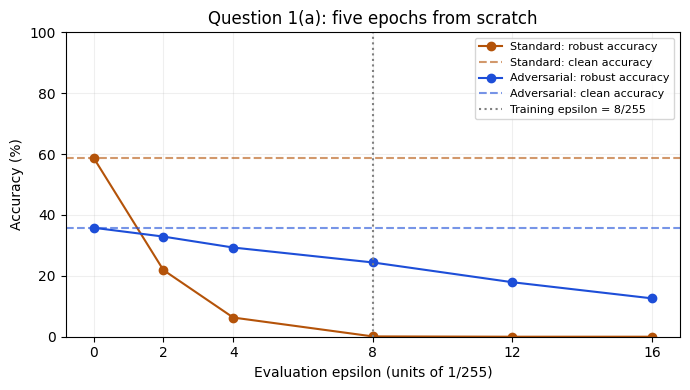


Saved checkpoints, training logs, CSV results and plot in: /content/hw3_q1a_outputs


In [8]:
# Fresh independent models with identical initial weights.
seed_all(SEED)
model_standard = make_model()
seed_all(SEED)
model_adversarial = make_model()
assert all(
    torch.equal(value, model_adversarial.state_dict()[name])
    for name, value in model_standard.state_dict().items()
)
assert all(
    p.data_ptr() != q.data_ptr()
    for p, q in zip(model_standard.parameters(), model_adversarial.parameters())
)

print("\nTraining STANDARD model from scratch")
model_standard, standard_history = train_q1a(
    model_standard, standard_loss, epochs=EPOCHS, seed=SEED
)
torch.save(model_standard.state_dict(), OUTPUT_DIR / "standard_5epochs.pt")
pd.DataFrame(standard_history).to_csv(
    OUTPUT_DIR / "standard_training_history.csv", index=False
)

print("\nTraining LINFINITY ADVERSARIAL model from scratch")
model_adversarial, adversarial_history = train_q1a(
    model_adversarial, adversarial_loss, epochs=EPOCHS, seed=SEED,
    eps=TRAIN_EPS, steps=TRAIN_STEPS,
)
torch.save(model_adversarial.state_dict(), OUTPUT_DIR / "adversarial_5epochs.pt")
pd.DataFrame(adversarial_history).to_csv(
    OUTPUT_DIR / "adversarial_training_history.csv", index=False
)

print("\nEvaluating both models at different epsilon values")
rows = []
for name, model in [
    ("Standard", model_standard),
    ("Adversarial", model_adversarial),
]:
    for eps_pixels in EVAL_EPS_PIXELS:
        scores = evaluate_q1a(
            model, eps=eps_pixels / 255,
            steps=EVAL_STEPS, restarts=EVAL_RESTARTS,
        )
        row = {
            "Model": name,
            "Evaluation epsilon": f"{eps_pixels}/255",
            "Epsilon in 1/255 units": eps_pixels,
            **scores,
        }
        rows.append(row)
        pd.DataFrame(rows).to_csv(OUTPUT_DIR / "q1a_results.csv", index=False)
        print(
            f"{name:12s} epsilon={eps_pixels:2d}/255 | "
            f"standard={scores['Standard accuracy (%)']:.2f}% | "
            f"robust={scores['PGD robust accuracy (%)']:.2f}%"
        )

results = pd.DataFrame(rows)
results["Accuracy drop (percentage points)"] = (
    results["Standard accuracy (%)"] - results["PGD robust accuracy (%)"]
)
results.to_csv(OUTPUT_DIR / "q1a_results.csv", index=False)
report_columns = [
    "Model", "Evaluation epsilon", "Standard accuracy (%)",
    "PGD robust accuracy (%)", "Accuracy drop (percentage points)",
]
print("\nQUESTION 1(a): RESULTS")
display(results[report_columns].round(2))

fig, ax = plt.subplots(figsize=(7, 4))
for name, color in [("Standard", "#B45309"), ("Adversarial", "#1D4ED8")]:
    frame = results[results["Model"] == name]
    ax.plot(
        frame["Epsilon in 1/255 units"], frame["PGD robust accuracy (%)"],
        marker="o", color=color, label=f"{name}: robust accuracy",
    )
    ax.axhline(
        frame["Standard accuracy (%)"].iloc[0],
        color=color, linestyle="--", alpha=0.6,
        label=f"{name}: clean accuracy",
    )
ax.axvline(8, color="gray", linestyle=":", label="Training epsilon = 8/255")
ax.set(
    xlabel="Evaluation epsilon (units of 1/255)", ylabel="Accuracy (%)",
    title="Question 1(a): five epochs from scratch", ylim=(0, 100),
    xticks=EVAL_EPS_PIXELS,
)
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "q1a_accuracy_vs_epsilon.png", dpi=200)
plt.show()

config = {
    "scope": "Question 1(a)", "seed": SEED, "epochs_per_model": EPOCHS,
    "training_epsilon": TRAIN_EPS, "training_PGD_steps": TRAIN_STEPS,
    "training_PGD_alpha": 2.5 * TRAIN_EPS / TRAIN_STEPS,
    "optimizer": "SGD", "lr": 0.01, "momentum": 0.9,
    "weight_decay": 5e-4, "batch_size": 128,
    "schedule": "CosineAnnealingLR, per optimizer step",
    "evaluation_PGD_steps": EVAL_STEPS, "evaluation_restarts": EVAL_RESTARTS,
    "evaluation_epsilon_pixels": EVAL_EPS_PIXELS,
    "train_images": len(y_train), "test_images": len(y_test),
    "initialization": "identical random weights from make_model(); no checkpoint loaded",
    "robust_accuracy": "clean correct and correct under every evaluated restart",
    "torch_version": str(torch.__version__), "device": str(device),
}
(OUTPUT_DIR / "experiment_settings.json").write_text(json.dumps(config, indent=2))
print("\nSaved checkpoints, training logs, CSV results and plot in:", OUTPUT_DIR.resolve())


In [9]:
#Question 1(b) — compare PGD and untargeted FGSM.

def evaluate_fgsm_q1b(model, eps, batch_size=250):
    model.eval()
    robust_total = 0

    for x, y in batches(x_test, y_test, batch_size, shuffle=False):
        with torch.no_grad():
            clean_correct = model(x).argmax(1).eq(y)

        if eps == 0:
            robust_correct = clean_correct
        else:
            x_adv = pgd_linf(
                model, x, y,
                eps=eps,
                alpha=eps,
                steps=1,
                rand_init=False,
            )

            with torch.no_grad():
                robust_correct = (
                    clean_correct & model(x_adv).argmax(1).eq(y)
                )

        robust_total += robust_correct.sum().item()

    return 100.0 * robust_total / len(y_test)

models_q1b = {
    "Standard": model_standard,
    "Adversarial": model_adversarial,
}


Standard     epsilon= 0/255 | clean=58.80% | PGD=58.80% | FGSM=58.80%
Standard     epsilon= 2/255 | clean=58.80% | PGD=21.90% | FGSM=26.80%
Standard     epsilon= 4/255 | clean=58.80% | PGD=6.30% | FGSM=12.80%
Standard     epsilon= 8/255 | clean=58.80% | PGD=0.10% | FGSM=3.70%
Standard     epsilon=12/255 | clean=58.80% | PGD=0.00% | FGSM=1.00%
Standard     epsilon=16/255 | clean=58.80% | PGD=0.00% | FGSM=0.70%
Adversarial  epsilon= 0/255 | clean=35.80% | PGD=35.80% | FGSM=35.80%
Adversarial  epsilon= 2/255 | clean=35.80% | PGD=32.90% | FGSM=32.90%
Adversarial  epsilon= 4/255 | clean=35.80% | PGD=29.30% | FGSM=29.40%
Adversarial  epsilon= 8/255 | clean=35.80% | PGD=24.40% | FGSM=24.70%
Adversarial  epsilon=12/255 | clean=35.80% | PGD=17.90% | FGSM=19.70%
Adversarial  epsilon=16/255 | clean=35.80% | PGD=12.60% | FGSM=15.40%


,Model,Evaluation epsilon,Clean accuracy (%),PGD accuracy (%),FGSM accuracy (%),PGD accuracy drop (pp),FGSM accuracy drop (pp)
0,Standard,0/255,58.8,58.8,58.8,0.0,0.0
1,Standard,2/255,58.8,21.9,26.8,36.9,32.0
2,Standard,4/255,58.8,6.3,12.8,52.5,46.0
3,Standard,8/255,58.8,0.1,3.7,58.7,55.1
4,Standard,12/255,58.8,0.0,1.0,58.8,57.8
5,Standard,16/255,58.8,0.0,0.7,58.8,58.1
6,Adversarial,0/255,35.8,35.8,35.8,0.0,0.0
7,Adversarial,2/255,35.8,32.9,32.9,2.9,2.9
8,Adversarial,4/255,35.8,29.3,29.4,6.5,6.4
9,Adversarial,8/255,35.8,24.4,24.7,11.4,11.1


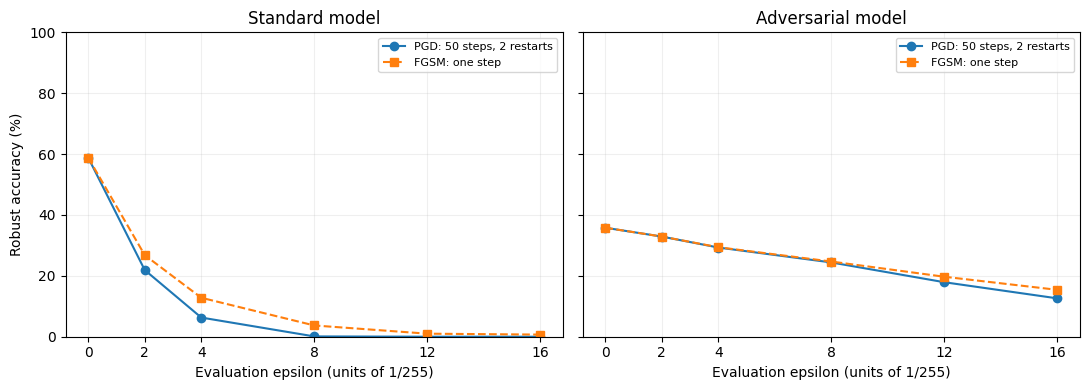

Saved: hw3_q1a_outputs/q1b_results.csv


In [10]:

# Reusing the PGD measurements already generated in Question 1(a).
rows_q1b = []

for _, previous in results.iterrows():
    name = previous["Model"]
    eps_pixels = int(previous["Epsilon in 1/255 units"])

    clean_acc = float(previous["Standard accuracy (%)"])
    pgd_acc = float(previous["PGD robust accuracy (%)"])

    fgsm_acc = evaluate_fgsm_q1b(
        models_q1b[name],
        eps=eps_pixels / 255,
    )

    rows_q1b.append({
        "Model": name,
        "Evaluation epsilon": f"{eps_pixels}/255",
        "Epsilon in 1/255 units": eps_pixels,
        "Clean accuracy (%)": clean_acc,
        "PGD accuracy (%)": pgd_acc,
        "FGSM accuracy (%)": fgsm_acc,
        "PGD accuracy drop (pp)": clean_acc - pgd_acc,
        "FGSM accuracy drop (pp)": clean_acc - fgsm_acc,
    })

    print(
        f"{name:12s} epsilon={eps_pixels:2d}/255 | "
        f"clean={clean_acc:.2f}% | "
        f"PGD={pgd_acc:.2f}% | FGSM={fgsm_acc:.2f}%"
    )

q1b_results = pd.DataFrame(rows_q1b)
q1b_results.to_csv(OUTPUT_DIR / "q1b_results.csv", index=False)

display(
    q1b_results.drop(columns="Epsilon in 1/255 units").round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, name in zip(axes, ["Standard", "Adversarial"]):
    frame = q1b_results[q1b_results["Model"] == name].sort_values(
        "Epsilon in 1/255 units"
    )

    ax.plot(
        frame["Epsilon in 1/255 units"],
        frame["PGD accuracy (%)"],
        marker="o",
        label="PGD: 50 steps, 2 restarts",
    )
    ax.plot(
        frame["Epsilon in 1/255 units"],
        frame["FGSM accuracy (%)"],
        marker="s",
        linestyle="--",
        label="FGSM: one step",
    )

    ax.set_title(f"{name} model")
    ax.set_xlabel("Evaluation epsilon (units of 1/255)")
    ax.set_xticks(EVAL_EPS_PIXELS)
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Robust accuracy (%)")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "q1b_pgd_vs_fgsm.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Saved:", OUTPUT_DIR / "q1b_results.csv")